<a href="https://colab.research.google.com/github/sajid-naeem-dev/student-marks-evaluation/blob/main/student_marks_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

      Name  Math  Science  English  Total  Average  Rank Status Grade
0   Zainab    96       94       99    289    96.33     1   Pass     A
1     Sara    93       90       95    278    92.67     2   Pass     A
2    Hamza    84       79       86    249    83.00     3   Pass     A
3     Hina    77       75       73    225    75.00     4   Pass     B
4  Ibrahim    72       65       76    213    71.00     5   Pass     B
5   Ayesha    68       71       64    203    67.67     6   Pass     C
6    Usman    60       53       65    178    59.33     7   Pass     D
7    Ahmad    50       55       57    162    54.00     8   Pass     D
8    Bilal    45       40       49    134    44.67     9   Pass     D
9      Ali    39       46       43    128    42.67    10   Pass     D

Class average: 68.63
Topper: Zainab with 289
Pass rate: 100.0 %

Subject statistics:
        Math  Science  English
count  10.00    10.00    10.00
mean   68.40    66.80    70.70
std    19.77    18.24    18.74
min    39.00    40.0

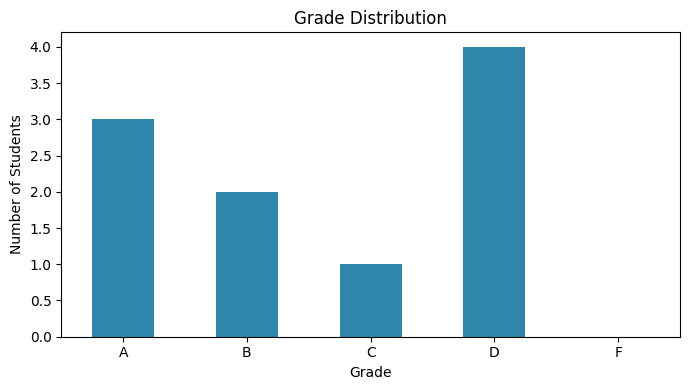

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Sample data (fake students)
data = {
    "Name":    ["Ali", "Ahmad", "Ibrahim", "Sara", "Hina", "Usman", "Zainab", "Bilal", "Ayesha", "Hamza"],
    "Math":    [34, 45, 67, 88, 72, 55, 91, 40, 63, 79],
    "Science": [41, 50, 60, 85, 70, 48, 89, 35, 66, 74],
    "English": [38, 52, 71, 90, 68, 60, 94, 44, 59, 81],
}
df = pd.DataFrame(data)
subjects = ["Math", "Science", "English"]

# 2. NumPy: add 5 bonus marks, capped at 100
BONUS = 5
marks = df[subjects].to_numpy()
final_marks = np.minimum(marks + BONUS, 100)

# 3. Pandas: build the results table
results = df[["Name"]].copy()
results[subjects] = final_marks
results["Total"] = results[subjects].sum(axis=1)
results["Average"] = results[subjects].mean(axis=1).round(2)
results["Rank"] = results["Total"].rank(ascending=False, method="min").astype(int)
results["Status"] = np.where(results["Average"] >= 40, "Pass", "Fail")
results["Grade"] = pd.cut(
    results["Average"],
    bins=[0, 40, 60, 70, 80, 101],
    labels=["F", "D", "C", "B", "A"],
    right=False,
).astype(str)

results = results.sort_values("Rank").reset_index(drop=True)
print(results)

# 4. Class summary
print("\nClass average:", round(results["Average"].mean(), 2))
print("Topper:", results.loc[0, "Name"], "with", results.loc[0, "Total"])
print("Pass rate:", round((results["Status"] == "Pass").mean() * 100, 1), "%")
print("\nSubject statistics:")
print(results[subjects].describe().round(2))

# 5. Export to Excel
results.to_excel("student_results.xlsx", index=False)

# 6. Grade distribution chart
grade_counts = results["Grade"].value_counts().reindex(["A", "B", "C", "D", "F"], fill_value=0)
plt.figure(figsize=(7, 4))
grade_counts.plot(kind="bar", color="#2E86AB")
plt.title("Grade Distribution")
plt.xlabel("Grade")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("grade_distribution.png", dpi=150)
plt.show()


In [ ]:
from google.colab import files
files.download("student_results.xlsx")
files.download("grade_distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("grade_distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>